In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import sys
sys.path.append('../../code')
from utils import *

<div dir="rtl">

# ברוכים הבאים לקורס סימולציה

## נתחיל עם שאלה פשוטה.

## אתם טילים מטבע עד שיוצא לכם גם עץ וגם פלי. גם הטלות בממוצע תצטרכו?

## ברור שהתשובה צריכה להיות יותר מ-2 כי במקרה הכי טוב זה יהיה 2, אם למשלייצא לנו עץ ואז פלי, או ההיפך פלי ואז עץ.

## אבל... ייתכן שייצא לנו למשל: עץ עץ עץ ורק אז פלי ואז יהיה לנו 4 נסיונות.

### ניתן לחשב את זה בעזרת תורת ההסתסברות. אבל אנחנו אם לא בטוחיםפ כיצד לעשות את זה, ניתן לחשב בעזרת סימולציה.

## הרעיון הכללי: נגריל מטבע עד שייצא לנו גם עץ וגם פלי, נספור כמה פעמים נדרשנו לעשות את זה, נחזור על זה הרבה פעמים ונעשה ממוצע.

In [2]:
num_trials = []

for ind in tqdm(range(100000)):

    chosen = []
    
    trials = 0
    while len(chosen) <=1:
        trials +=1
        res = np.random.choice(['pali', 'etz']).item()
        if res not in chosen:
            chosen.append(res)

    num_trials.append(trials)
    


100%|████████████████████████████████████████████████████████████████████████████| 100000/100000 [00:10<00:00, 9837.77it/s]


In [3]:
np.array(num_trials).mean()       

np.float64(3.00113)

<div dir="rtl">

## קיבלנו ערך מאד קרוב ל-3. 

## אם היינו רוצים לחשב את זה הסברותית היינ מקבלים בדיוק 3.

### הסבר: נחלק לשני שלבים, עד שנקבל ערך אחד, והשלב השני עד שנקבל שני ערכים שונים.

### נגדיר: $E[Y]$ התוחלת הכוללת לקבלת שני ערכים שונים

### נפצל: $E[Y] = E[X_1] + E[X_2] $

### כאשר: $E[X_1[$ התוחלת של השלב הראשון

### כאשר: $E[X_2[$ התוחלת של השלב השני

### השלב הראשון: תמיד בפעם הראשונה ניפול על צד שלא קיבלנו עדיין - לכן צמיד מספר ההטלות יהיה 1 ולכן גם התוחלת היא 1 

### $E[X_1] = 1$ 

### ואילו השלב השני הוא מ"מ גיאומטרי עם הסתברות חצי.

### תוחלת של מ"מ גיאומטרי זה :

## $$ X_2\sim G(p), E[X_2] = \frac{1}{p} $$

### במקרה שלנו:

## $$ X\sim G(0.5), E[X] = \frac{1}{0.5} = 2 $$

## לכן:

### $$  E[Y] = \frac{1}{0.5} = 2 $$

<div dir="rtl">


## משפט הגבול המרכזי:

### ידוע כי כל מ"מ יש לו צורת התפלגות אחרת 

## להלן כמה דוגמאות: 

<div dir="rtl">

## דוגמאות להתפלגויות ולמשפט הגבול המרכזי

### נבחר חמש התפלגויות: בינומית, גיאומטרית, מעריכית, Erlang, ו-PH מסוג Hyper-Erlang.

### לכל התפלגות נציג תחילה את פונקציית ההסתברות/הצפיפות התאורטית ליד היסטוגרמה של 100,000 הגרלות. לאחר מכן נגריל 10,000 ממוצעים, כאשר כל ממוצע מבוסס על 50 הגרלות בלתי תלויות, ונראה איך ההתפלגות של הממוצעים מתחילה להיראות נורמלית.

</div>

In [ ]:
import math

sample_size = 100_000
mean_repetitions = 10_000
mean_sample_size = 50
rng = np.random.default_rng(42)



hyper_erlang_branches = [
    {"prob": 0.55, "shape": 2, "rate": 1.8},
    {"prob": 0.45, "shape": 6, "rate": 0.9},
]
hyper_mean = sum(branch["prob"] * branch["shape"] / branch["rate"] for branch in hyper_erlang_branches)
hyper_second_moment = sum(
    branch["prob"] * branch["shape"] * (branch["shape"] + 1) / branch["rate"] ** 2
    for branch in hyper_erlang_branches
)

distributions = [
    {
        "name": "Binomial(n=20, p=0.35)",
        "kind": "discrete",
        "support": np.arange(21),
        "density": lambda x: np.array([math.comb(20, int(k)) * 0.35 ** int(k) * 0.65 ** (20 - int(k)) for k in x]),
        "sample": lambda size: rng.binomial(20, 0.35, size=size),
        "mean": 20 * 0.35,
        "variance": 20 * 0.35 * 0.65,
    },
    {
        "name": "Geometric(p=0.25)",
        "kind": "discrete",
        "support": np.arange(1, 31),
        "density": lambda x: 0.25 * 0.75 ** (x - 1),
        "sample": lambda size: rng.geometric(0.25, size=size),
        "mean": 1 / 0.25,
        "variance": 0.75 / 0.25 ** 2,
    },
    {
        "name": "Exponential(rate=1.2)",
        "kind": "continuous",
        "support": np.linspace(0, 8, 500),
        "density": lambda x: 1.2 * np.exp(-1.2 * x),
        "sample": lambda size: rng.exponential(1 / 1.2, size=size),
        "mean": 1 / 1.2,
        "variance": 1 / 1.2 ** 2,
    },
    {
        "name": "Erlang(k=4, rate=1.0)",
        "kind": "continuous",
        "support": np.linspace(0, 16, 500),
        "density": lambda x: erlang_pdf(x, shape=4, rate=1.0),
        "sample": lambda size: rng.gamma(shape=4, scale=1 / 1.0, size=size),
        "mean": 4 / 1.0,
        "variance": 4 / 1.0 ** 2,
    },
    {
        "name": "Hyper-Erlang PH",
        "kind": "continuous",
        "support": np.linspace(0, 18, 500),
        "density": lambda x: hyper_erlang_pdf(x, branches=hyper_erlang_branches),
        "sample": lambda size: sample_hyper_erlang(size, hyper_erlang_branches, rng),
        "mean": hyper_mean,
        "variance": hyper_second_moment - hyper_mean ** 2,
    },
]


<div dir="rtl">

### צפיפות/הסתברות תאורטית מול היסטוגרמת הגרלות

### בגרפים הבאים, הצד השמאלי הוא ההתפלגות התאורטית, והצד הימני הוא היסטוגרמה מנורמלת של 100,000 הגרלות מאותה התפלגות.

</div>

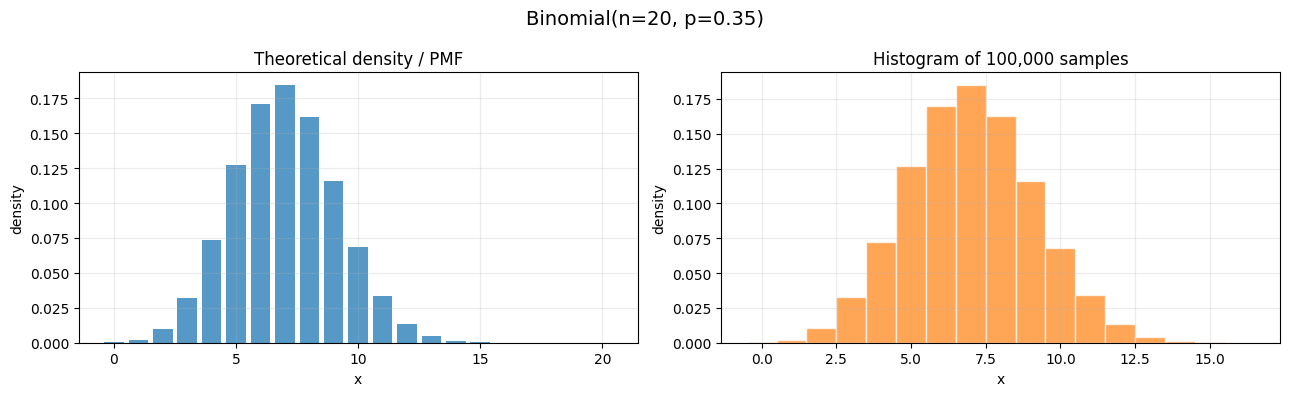

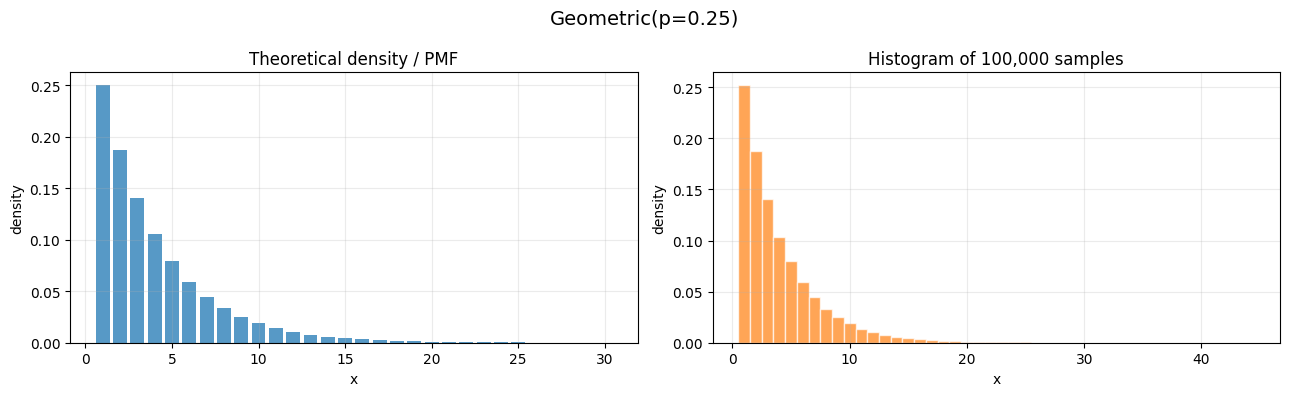

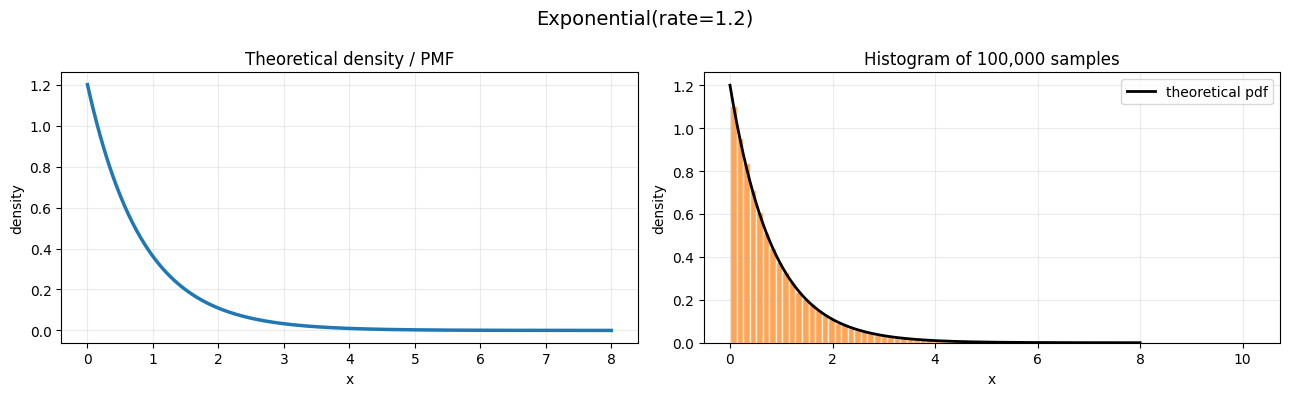

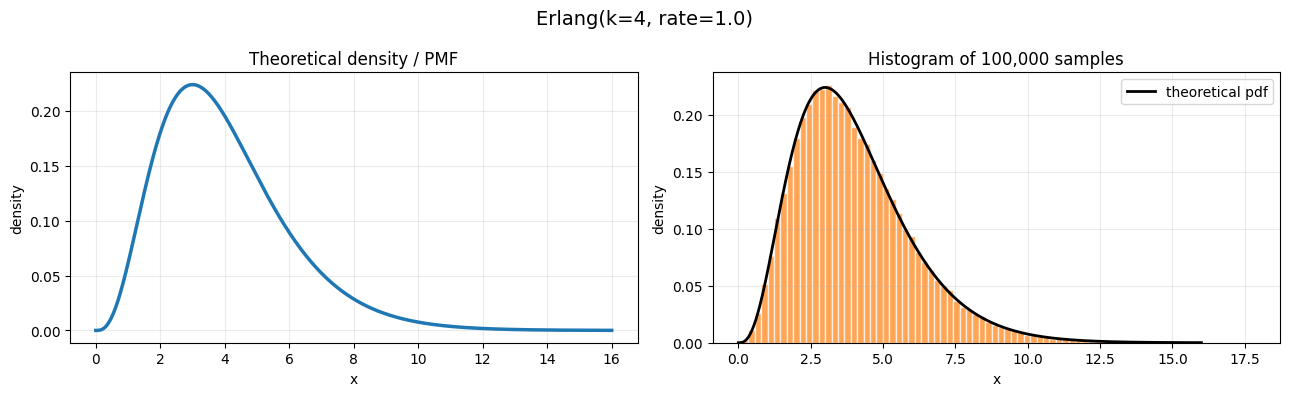

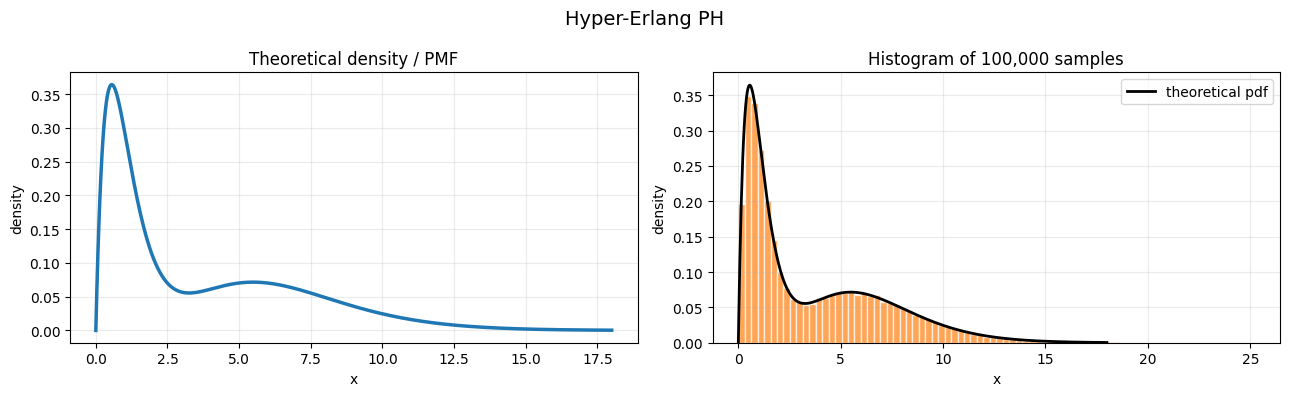

In [4]:
for distribution in distributions:
    plot_distribution_vs_samples(distribution, sample_size)


<div dir="rtl">

### משפט הגבול המרכזי: היסטוגרמות של ממוצעים

### כעת עבור כל התפלגות נחשב 10,000 ממוצעים, כאשר כל ממוצע הוא ממוצע של 50 הגרלות. הצד השמאלי עדיין מציג את ההתפלגות המקורית, והצד הימני מציג את היסטוגרמת הממוצעים. הקו השחור המקווקו הוא קירוב נורמלי עם אותה תוחלת ושונות מתאימות לממוצע.

</div>

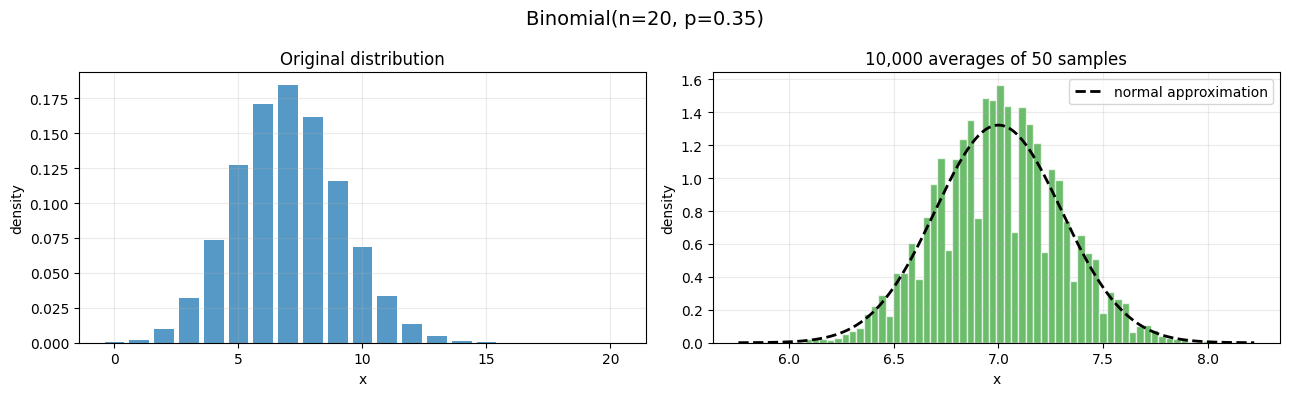

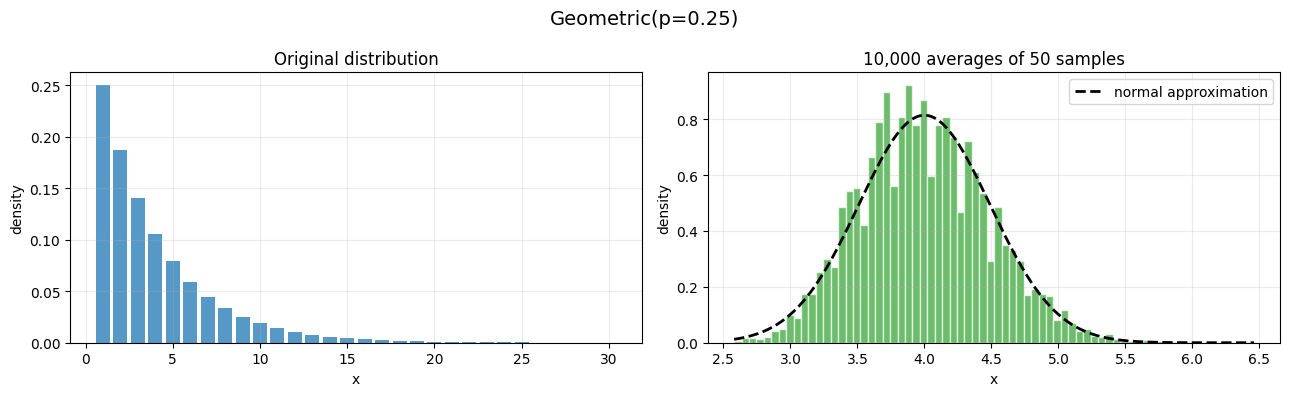

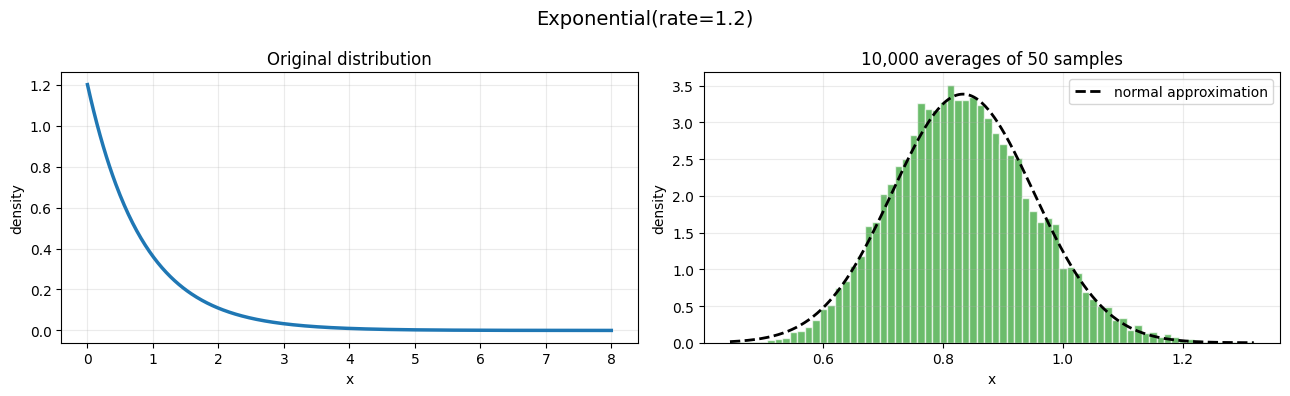

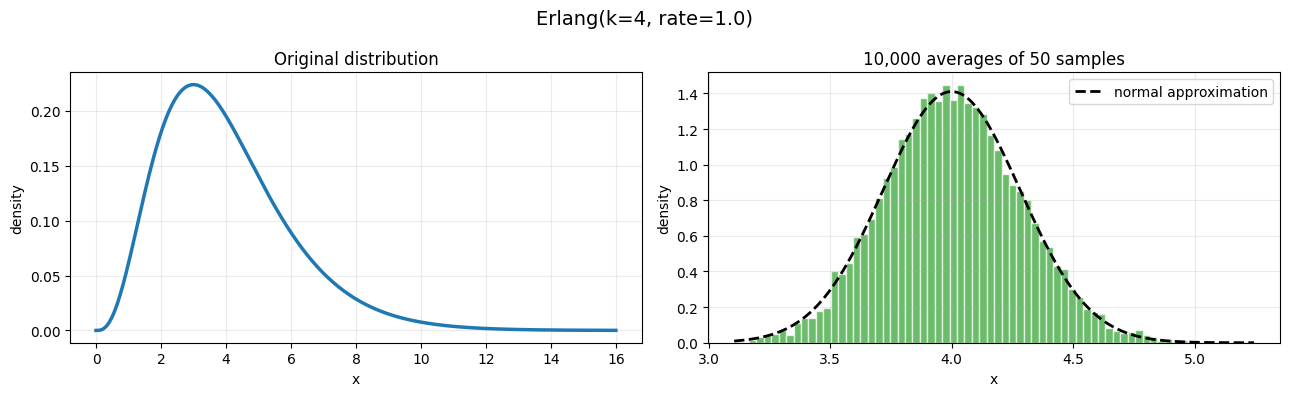

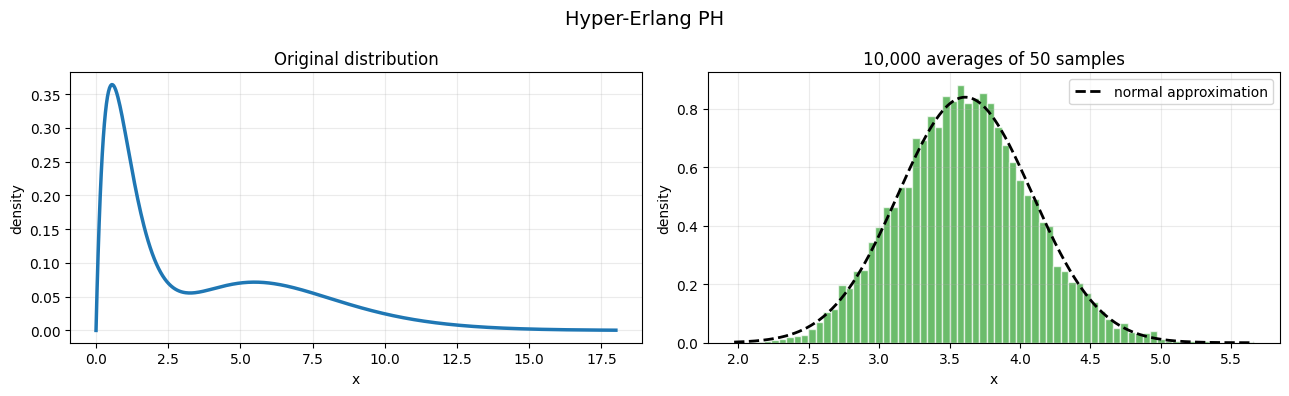

In [5]:
for distribution in distributions:
    plot_original_vs_sample_means(distribution, mean_repetitions, mean_sample_size)


<div dir="rtl">

### התכנסות הממוצעים עבור Hyper-Erlang

### כעת ניקח רק את התפלגות ה-Hyper-Erlang ונבדוק איך התפלגות הממוצעים משתנה כאשר מספר ההגרלות בכל ממוצע הוא 2, 5, 10, 30 ו-50. בכל מקרה נחשב 10,000 ממוצעים ונציג את ההיסטוגרמה שלהם.

</div>

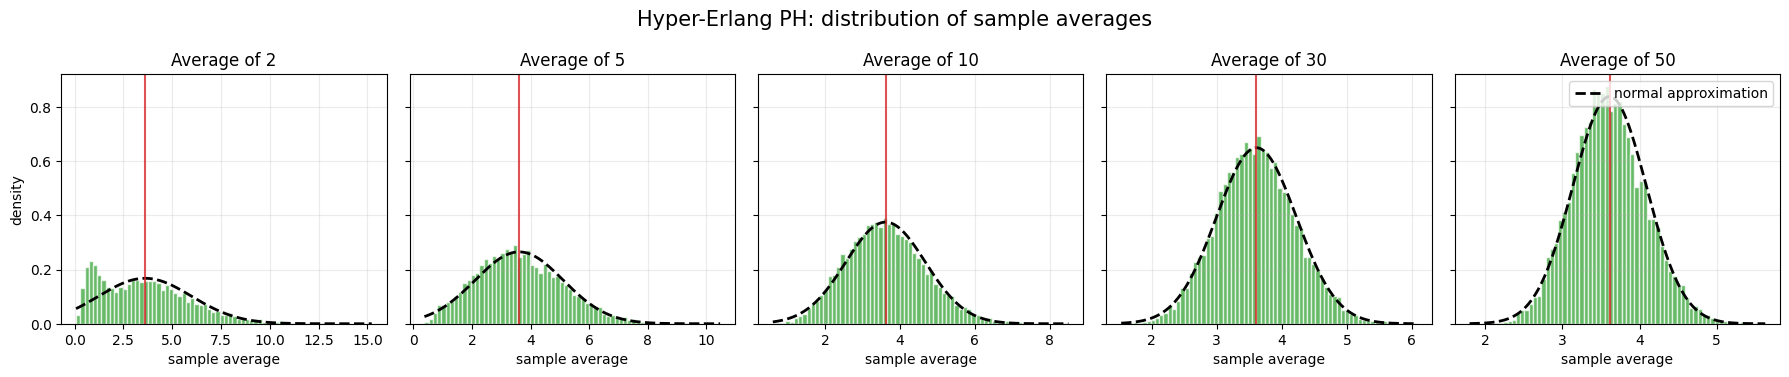

In [6]:
hyper_erlang_distribution = next(
    distribution for distribution in distributions
    if distribution["name"] == "Hyper-Erlang PH"
)

average_sample_sizes = [2, 5, 10, 30, 50]
fig, axes = plt.subplots(1, len(average_sample_sizes), figsize=(18, 3.8), sharey=True)
fig.suptitle("Hyper-Erlang PH: distribution of sample averages", fontsize=15)

for ax, average_sample_size in zip(axes, average_sample_sizes):
    values = hyper_erlang_distribution["sample"](mean_repetitions * average_sample_size)
    means = values.reshape(mean_repetitions, average_sample_size).mean(axis=1)

    mean_of_average = hyper_erlang_distribution["mean"]
    std_of_average = np.sqrt(hyper_erlang_distribution["variance"] / average_sample_size)
    normal_support = np.linspace(means.min(), means.max(), 500)

    ax.hist(means, bins=70, density=True, color="tab:green", alpha=0.72, edgecolor="white")
    ax.plot(
        normal_support,
        normal_pdf(normal_support, mean_of_average, std_of_average),
        "k--",
        linewidth=2,
        label="normal approximation",
    )
    ax.axvline(mean_of_average, color="tab:red", linewidth=1.5, alpha=0.8)
    ax.set_title(f"Average of {average_sample_size}")
    ax.set_xlabel("sample average")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("density")
axes[-1].legend(loc="upper right")
plt.tight_layout()
plt.show()


<div dir="rtl">

## שאלה: נחלק את הכיתה ל-2 קבוצות.

### קבוצה 1 מטילה מטבע עד שיוצא לך עץ פלי פלי

### קבוצה 2 מטילה מטבע עד שיותא לה עץ פלי פלי.

### כל קבוצה קבוצה מטילה מטבע וסופרת כמה הטלות נדרשו לה עד שהגיעה ליעד. 

### למשל עבור קבוצה 1: עץ פלי פלי:  התקבל הרצף הבא

### עץ פלי עץ פלי פלי

### כלומר נדרשו 5 הטלות.

### השאלה היא איזו קבוצה תידרש ליותר הטלות: 
#### א. קבוצה 1
#### ב. קבוצה 2
#### ג. אותו דבר - קלללל

<div dir="rtl">

### לא בטוחים? בואו נחשב. 

### את התשובה ניתן לחשב על ידי שרשרת מרקוב - אבל אנחנו לא בעסקי הפתרונות המתמטיים אלא בעסקי הסימולציה.

### אז בואו נחשב. נתחיל עם קבוצה 1. 

### נבנה פונקציה שמחזירה את כמות ההטלות עד שמגיעים לרצף רצוי  .

In [24]:
np.random.choice(['heads', 'tail']).item()

'heads'

In [43]:
target1 = ['heads', 'tail', 'tail']
target2 = ['heads', 'tail', 'heads']

In [35]:
def num_seq(target):


    res_samples = []
    

    while target != res_samples[-3:]:
      
        curr_sample = np.random.choice(['heads', 'tail']).item()
        res_samples.append(curr_sample)
    
    return len(res_samples) 



8

In [44]:
num_trials1 = []
num_trials2 = []

for ind in tqdm(range(25000)):
    num_trials1.append(num_seq(target1))

for ind in tqdm(range(25000)):
    num_trials2.append(num_seq(target2))

100%|██████████████████████████████████████████████████████████████████████████| 25000/25000 [00:02<00:00, 9180.00it/s]


In [45]:
np.array(num_trials1).mean(), np.array(num_trials2).mean()

(np.float64(7.98204), np.float64(9.94116))

<div dir="rtl">

## קבוצה 1 קיבלה ממוצע באיזור 8 ואילו קבוצה 2 קיבלה באיזור 10.

# למה?????????